In [ ]:
Practical No:7
Roll no: 46
Title:Interacting with Web APIs 
Analyzing Weather Data from OpenWeatherMap API 

In [8]:
!pip install requests pandas matplotlib


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
API_KEY = "1d2f73d975a6b88dd3dbe6cd2efc7f64"
CITY = "Pune"

url = "https://api.openweathermap.org/data/2.5/weather"

In [11]:
params = {
    "q": CITY,
    "appid": API_KEY,
    "units": "metric"
}

response = requests.get(url, params=params)


In [12]:
if response.status_code == 200:
    data = response.json()

    temperature = data["main"]["temp"]
    humidity = data["main"]["humidity"]
    pressure = data["main"]["pressure"]
    weather = data["weather"][0]["description"]
    wind_speed = data["wind"]["speed"]

In [13]:
print("City:", CITY)
print("Temperature:", temperature, "°C")
print("Humidity:", humidity, "%")
print("Pressure:", pressure, "hPa")
print("Weather:", weather)
print("Wind Speed:", wind_speed, "m/s")


City: Pune
Temperature: 32.8 °C
Humidity: 26 %
Pressure: 1015 hPa
Weather: clear sky
Wind Speed: 3.4 m/s


In [16]:
df = pd.DataFrame({
        "Parameter": ["Temperature", "Humidity",
                      "Pressure", "Wind Speed"],
        "Value": [temperature, humidity,
                  pressure, wind_speed]
})

print("\nWeather Data:")
print(df)


Weather Data:
     Parameter   Value
0  Temperature    32.8
1     Humidity    26.0
2     Pressure  1015.0
3   Wind Speed     3.4


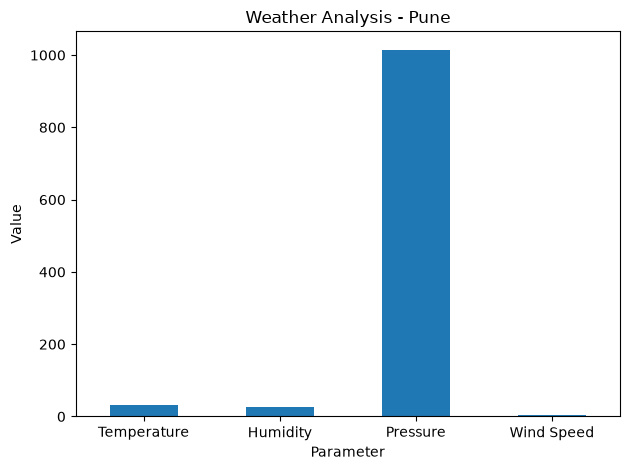

In [22]:
if response.status_code == 200:

    df.plot(x="Parameter", y="Value",
            kind="bar", legend=False)

    plt.title("Weather Analysis - " + CITY)
    plt.ylabel("Value")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

else:
    print("Error:", response.status_code)
    print(response.json().get("message", "Unable to fetch data"))